# 1 · The port, and where the numbers come from

Every euro figure this project produces traces back to two public sources and one
audited document. This notebook shows that derivation, because a risk model whose
inputs cannot be traced is an opinion with decimal places.

**The port.** Rønne, on Bornholm. Chosen because it is the real thing rather than a
scaled-down proxy: 34 employees, sole supply port for an island, genuinely mixed
traffic. It sits *below* NIS2's size threshold — and in scope anyway under Article
2(2)(b), which catches sole providers of essential services regardless of size.
Legally obligated, operationally critical, far too small to run a security function.
That is precisely the organisation this DSS is for.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from portscra.viz import PALETTE, INK_MUTED, style, label_bars, despine
style()

def short(text, limit=30):
    "Trim to a word boundary — a label cut mid-word reads as a rendering bug."
    if len(text) <= limit:
        return text
    cut = text[:limit].rsplit(" ", 1)[0]
    return (cut or text[:limit]) + "…"

In [2]:
from portscra.risk import RONNE_2024, OutageCostPerHour

e = RONNE_2024
print(f"{e.name}, {e.year}")
print(f"  revenue          EUR {e.revenue_eur:>12,.0f}")
print(f"  EBITDA           EUR {e.ebitda_eur:>12,.0f}   margin {e.ebitda_margin:.0%}")
print(f"  ship calls       {e.annual_calls:>16,}")
print(f"  revenue per call EUR {e.revenue_per_call_eur:>12,.0f}")
print(f"  employees        {e.employees_fte:>16} FTE")
print(f"\nsource: {e.source}")

Rønne Havn A/S, 2024
  revenue          EUR   22,762,153
  EBITDA           EUR   13,627,992   margin 60%
  ship calls                  3,043
  revenue per call EUR        7,480
  employees                      34 FTE

source: Rønne Havn A/S Årsrapport 2024 (CVR 27932150), income statement p.34 and five-year overview p.22; call count from Danmarks Statistik SKIB101, HAVN=00315.


## Traffic, from AIS

The Danish Maritime Authority publishes daily AIS for all Danish waters, free and
without registration. Four full weeks — one per season — were downloaded, filtered
to Rønne, and reduced to port calls. About 18 GB in, 82 kB out.

Two corrections were needed along the way, both caught by checking the output
against reality rather than by inspecting the code:

* The bounding box was capturing the **marina**. Commercial berths sit at latitude
  55.0875–55.0994 and recreational craft at 55.1033–55.1056 — a clean split, so the
  box was cut at 55.100. Before that, 29 of 50 vessels in a July day were yachts.
* The truncation tolerance was **tighter than AIS itself**. A moored Class A vessel
  transmits every 3 minutes, so a ship already alongside at midnight often produced
  its first message at 00:02 and was recorded as a fresh arrival. The dwell p90 was
  pinned at 23.9 h as a result — an artefact of the observation window, not a berth
  pattern.

In [3]:
from portscra.ais import reflag_truncation, stitch_across_days

calls = pd.read_parquet("../data/processed/portcalls-all.parquet")
calls["date"] = pd.to_datetime(calls["date"])
calls = stitch_across_days(reflag_truncation(calls))

COMMERCIAL = {"Passenger", "HSC", "Cargo", "Tanker", "Ro-Ro", "Reefer"}
ronne = calls[calls.port == "ronne"].copy()
ronne["commercial"] = ronne.ship_type.isin(COMMERCIAL)

SEASONS = {"winter": "2026-01-19", "spring": "2026-04-13",
           "autumn": "2025-10-13", "summer": "2026-07-20"}
def season_of(ts):
    for name, start in SEASONS.items():
        s = pd.Timestamp(start)
        if s <= ts <= s + pd.Timedelta(days=6): return name
    return "other"
ronne["season"] = ronne.arrival.dt.normalize().apply(season_of)

per_day = (ronne[ronne.commercial].groupby("season").size() / 7).reindex(
    ["winter", "spring", "autumn", "summer"])
print(per_day.round(1).to_string())
print(f"\nseasonal swing: {per_day.max() / per_day.min():.2f}x")

season
winter    4.0
spring    5.3
autumn    7.0
summer    7.9

seasonal swing: 1.96x


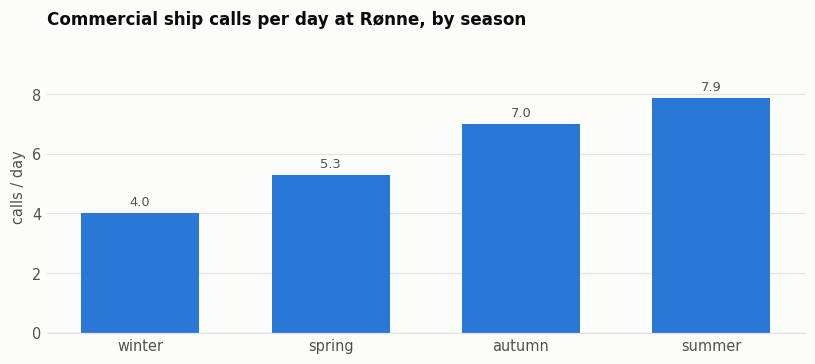

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
bars = ax.bar(per_day.index, per_day.values, color=PALETTE["blue"], width=0.62)
label_bars(ax, bars, per_day.values, "{:.1f}")
ax.set_title("Commercial ship calls per day at Rønne, by season")
ax.set_ylabel("calls / day")
ax.set_ylim(0, per_day.max() * 1.25)
despine(ax); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

A **1.96× swing** between winter and summer. Autumn nearly matches summer, which is
not tourism — it is the offshore-wind installation season, when the weather is still
workable. A consequence model calibrated on July alone would overstate January risk
by about half.

## Does the detector measure the right thing?

The AIS-derived call count is checked against Danmarks Statistik's official series
for Rønne (table SKIB101). Our two vessel-type definitions **bracket** the official
figure, which is a better result than any single ratio: the official series counts
more than our strict commercial set — it will include fishing, tugs and service
craft — but less than everything including yachts.

In [5]:
days = calls.date.nunique()
commercial_yr = ronne.commercial.sum() / days * 365
all_yr = len(ronne) / days * 365
official = {2024: 3043, 2025: 2933}

print(f"commercial calls  {commercial_yr:>7,.0f} / yr")
print(f"all vessel calls  {all_yr:>7,.0f} / yr")
for year, count in official.items():
    inside = commercial_yr <= count <= all_yr
    print(f"official {year}     {count:>7,} / yr   "
          f"{'within our bracket' if inside else 'OUTSIDE'}")

commercial calls    2,203 / yr
all vessel calls    4,954 / yr
official 2024       3,043 / yr   within our bracket
official 2025       2,933 / yr   within our bracket


## Dwell times → the consequence model's inputs

How long a vessel occupies a berth sets how long an outage has to last before it
starts turning ships away rather than merely delaying them. Read as
`PERT(p10, median, p90)`, these become the model's three-point estimates.

The Passenger median of **2.7 hours** is the strongest validation the pipeline has
produced: that is a real ro-pax turnaround, and it matches the HAMMERSHUS calls
observed directly on day one. Before the two corrections above it read 9.0 hours —
pure contamination from vessels that were present all day.

In [6]:
complete = ronne[ronne.commercial & ~ronne.truncated_start & ~ronne.truncated_end]
dwell = (complete.groupby("ship_type").dwell_hours
         .agg(n="count", p10=lambda s: s.quantile(.1), median="median",
              p90=lambda s: s.quantile(.9))
         .query("n >= 5").sort_values("median"))
print(dwell.round(2).to_string())

            n   p10  median    p90
ship_type                         
Passenger  47  1.87    2.13  11.10
HSC        21  1.36    2.35   2.62
Cargo      12  2.06    5.36  13.20


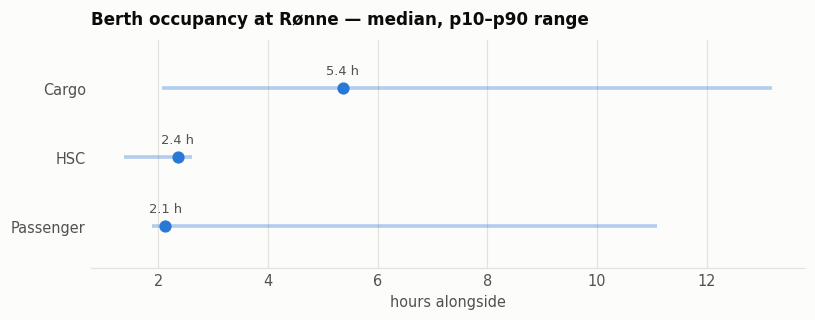

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.0))
y = np.arange(len(dwell))
ax.hlines(y, dwell.p10, dwell.p90, color=PALETTE["blue"], lw=2.4, alpha=.35)
ax.plot(dwell["median"], y, "o", color=PALETTE["blue"], ms=7, zorder=3)
for i, (name, row) in enumerate(dwell.iterrows()):
    ax.annotate(f"{row['median']:.1f} h", (row["median"], i), xytext=(0, 9),
                textcoords="offset points", ha="center",
                color=INK_MUTED, fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels(dwell.index)
ax.set_title("Berth occupancy at Rønne — median, p10–p90 range")
ax.set_xlabel("hours alongside")
ax.set_ylim(-.6, len(dwell) - .3)
despine(ax); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## From revenue to a cost per outage hour

Two reductions, both uncertain, so both are distributions rather than point values:

* **Not all revenue is at risk.** A cyber outage stops vessel handling. It does not
  stop the clock on land leases and project-area rental, which are billed on time
  and which grew sharply at Rønne in 2024.
* **Not all disrupted revenue is lost.** A cancelled ferry carries tomorrow's
  passengers too. What is genuinely lost is traffic that diverts, the cruise call
  that cannot be rescheduled, the offshore project window that closes.

In [8]:
cost = OutageCostPerHour(RONNE_2024)
draws = cost.sample(np.random.default_rng(42), 200_000)
print(f"cost per outage hour: EUR {cost.mean:,.0f} mean "
      f"(P10 {np.percentile(draws,10):,.0f} / P90 {np.percentile(draws,90):,.0f})")

check = cost.cross_check_per_call(RONNE_2024.annual_calls / 365)
print(f"\nindependent derivation via revenue per call: "
      f"EUR {check['adjusted_hourly_eur']:,.0f}/h  (ratio {check['ratio']:.2f})")

cost per outage hour: EUR 659 mean (P10 451 / P90 883)

independent derivation via revenue per call: EUR 659/h  (ratio 1.00)


The two derivations agree to **ratio 1.00** on a matched call basis. That check paid
for itself the first time it ran: it caught a 15× unit error where daily revenue was
being converted to hourly with `×24` instead of `×365/service_hours`.

**€659/hour** is roughly a quarter of the placeholder used before this derivation
existed — and that difference reorders the risks, as notebook 3 shows.